# long-job cancellation: Methods and evidence

**Level:** 1 **Prerequisites:** 02-learned-action-policies **Reading time:** 15 minutes

**Question:** How do policy decisions and the task oracle describe the long-job cancellation case C07?

## Objectives

This lesson investigates the question: How do policy decisions and the task oracle describe the long-job cancellation case C07?

## Setup

The versions below are pinned in `notebooks/requirements.txt` and are also recorded in this notebook's metadata;

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```

In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")
import sys
ROOT = Path('../../../').resolve()
sys.path.insert(0, str(ROOT))
checkpoint_dir = Path(os.environ.get('NEURAXIS_CHECKPOINTS', str(ROOT / 'models/checkpoints')))
planner_model = os.environ.get('NEURAXIS_NOTEBOOK_MODEL')
planner = OllamaPlanner(planner_model) if planner_model else None
sys.path.insert(0, str(ROOT / 'notebooks'))

reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Data
The notebook reads committed product artifacts. Owner: Neuraxis. Repository: https://github.com/fsantibanezleal/CAOS_Neuraxis. License: Apache-2.0. The JSON is a first-party, frozen experiment artifact; no external benchmark data are redistributed in this notebook;

This notebook reads `data/derived/index.json` and the listed trace artifacts. The method run uses an isolated Reflexmesh case workspace; For learned methods, fetch the exact public release assets with `python -m reflexmesh; Cli fetch-models --destination models/checkpoints --version v0; 01.000`, then set `NEURAXIS_CHECKPOINTS` to that folder; The release manifest verifies asset hashes. Planner methods M09/M10 are read from frozen traces unless `NEURAXIS_NOTEBOOK_MODEL` explicitly names a configured local Ollama model;

Artifacts for this lesson:

- `data/derived/index.json` - `data/derived/benchmark-adequacy.json` - `data/derived/episodes/M05-C07-nominal-40000; - `data/derived/episodes/M06-C07-nominal-40000; - `data/derived/episodes/M07-C07-nominal-40000; - `data/derived/episodes/M08-C07-nominal-40000;json`

## Method

Trace decisions across the changing C07 process state. The task is not one classification: waiting, observing job completion, honoring cancellation and checking the final postcondition form a time-ordered control problem with measurable effects. C07 is a temporal control problem:

### long-job cancellation · level 1 | Verify the audit and each trace's bytes before interpreting outcomes.

In [2]:
# Load manifest-verified evidence and keep failures in every denominator.
import sys
sys.path.insert(0, str(ROOT / 'notebooks'))
from lesson_support import load_lesson_evidence
selected_methods = trace_methods = ['M05', 'M06']
sample_case, seed = 'C07', 40000
evidence = load_lesson_evidence(
    ROOT, topic='03-sequential-control', methods=tuple(trace_methods),
    sample_case=sample_case, seed=seed,
    include_core=False, include_transfer=False,
)
index, audit = evidence['index'], evidence['audit']
records, case_records = evidence['records'], evidence['case_records']
print('Hash-verified records:', len(records), '| case variants:', len(case_records))


Hash-verified records: 2 | case variants: 12


### Inspect one guarded trace: read both fields in the trace.

The cancellation environment exposes asynchronous progress as successive observations. A request to cancel is only an attempted action; the environment's later terminal state is the evidence that the job stopped. Read the event history in order and check whether a policy polls after a cancellation request, accepts a completion race, or exits before the verifier observes termination. The worked trace illustrates this distinction, not the frequency of race conditions in production systems.

### long-job cancellation · L1 | Build the first executable policy

In level 1, construct policy M01 for long-job cancellation with the public factory and keep its observation contract unchanged before sampling C07.

In [3]:
# Construct the first released policy through the public factory.
primary_id = 'M05'
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M05


### long-job cancellation · L1 | Execute the primary method on the named case

The long-job cancellation evaluator runs M01 on C07 and derives success from the independent task postcondition, not from a replayed trace.

In [4]:
# Run the policy and verify the case postcondition independently.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### long-job cancellation · L1 | Construct an independent comparison policy

For the long-job cancellation example on C07, create M02 as a fresh object so recurrent state from M01 cannot leak into the matched comparison.

In [5]:
# Create a fresh policy object for the matched comparison.
secondary_id = 'M06'
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M06


### long-job cancellation · L1 | Run the comparison under identical conditions

Within this one-case long-job cancellation run (C07), this level 1 comparison runs M02 on the same C07, nominal variant and seed, and it illustrates behavior rather than estimating a population rate.

In [6]:
# Use the same case, variant and seed for the second policy.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### long-job cancellation · L1 | Aggregate the two executed episodes

In the single-run long-job cancellation exercise on C07, the package aggregator summarizes two executed long-job cancellation episodes, and cross-family claims still require the complete benchmark below.

In [7]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### long-job cancellation · L1 | Fresh policy outcomes

For the long-job cancellation example on C07, the next plot is computed from the long-job cancellation episode results just executed for C07 rather than copied from a frozen artifact.

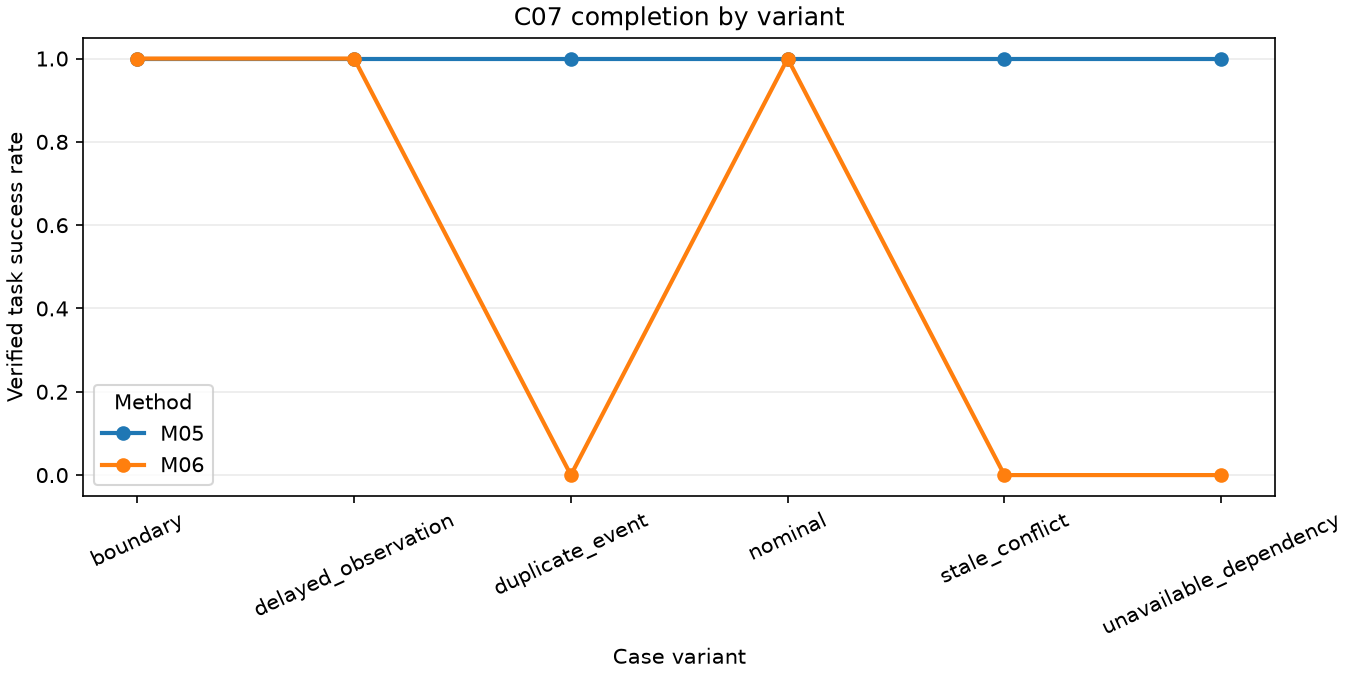

In [8]:
# Compare verified completion rates over every seed in each case variant.
methods_to_plot = selected_methods
variants = sorted({variant for _, variant in case_records})
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in methods_to_plot:
    rates = []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        rate = sum(bool(e['metrics']['task_success']) for e in episodes) / len(episodes) if episodes else float('nan')
        rates.append(rate)
    ax.plot(variants, rates, marker='o', linewidth=2, label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Verified task success rate")
ax.set_xlabel("Case variant")
ax.set_title(sample_case + " completion by variant")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(title='Método' if False else 'Method')
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


For long-job cancellation, these bars show fresh task-postcondition outcomes for M01 and M02 on C07, with success encoded as 1 and failure as 0. Read the case and seed before comparing them. In the single-run long-job cancellation exercise on C07, this controlled episode illustrates policy behavior but is not a confidence interval and does not establish generalization to other software tasks;

## Results

**Answer:** The long-job cancellation example executes 2 policies, M05 and M06, on C07; read both fields in the trace.

All 40 M12 failures are in C07, while several methods succeed on all 200 C07 episodes; The result identifies a concrete gap; Within this one-case long-job cancellation run (C07), aggregate success alone does not establish whether recurrence, action masking, model error or cancellation timing caused it;

## Summary

A cancellation request and a verified stopped job are distinct events in C07.




## References
- [GRU](https://arxiv.org/abs/1406.1078) - [PPO](https://arxiv.org/abs/1707.06347) - [LINUCB](https://arxiv.org/abs/1003.0146)